First Five Rows:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

Missing Values
age         0
sex         0
bmi      

/tmp/ipykernel_1501/2721840265.py:43: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)
/tmp/ipykernel_1501/2721840265.py:41: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try us

Epoch [20/300] Loss = 0.833437
Epoch [40/300] Loss = 0.541503
Epoch [60/300] Loss = 0.263232
Epoch [80/300] Loss = 0.186712
Epoch [100/300] Loss = 0.155070
Epoch [120/300] Loss = 0.147786
Epoch [140/300] Loss = 0.143386
Epoch [160/300] Loss = 0.139858
Epoch [180/300] Loss = 0.136670
Epoch [200/300] Loss = 0.133572
Epoch [220/300] Loss = 0.130539
Epoch [240/300] Loss = 0.127650
Epoch [260/300] Loss = 0.124776
Epoch [280/300] Loss = 0.121811
Epoch [300/300] Loss = 0.118556

Evaluation Metrics
Mean Squared Error : 19614124.0
Root Mean Squared Error : 4428.783580171874
Mean Absolute Error : 2514.954833984375
R2 Score : 0.8736599683761597


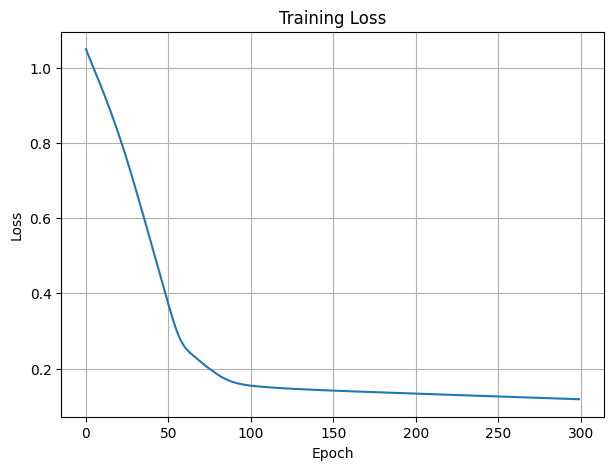

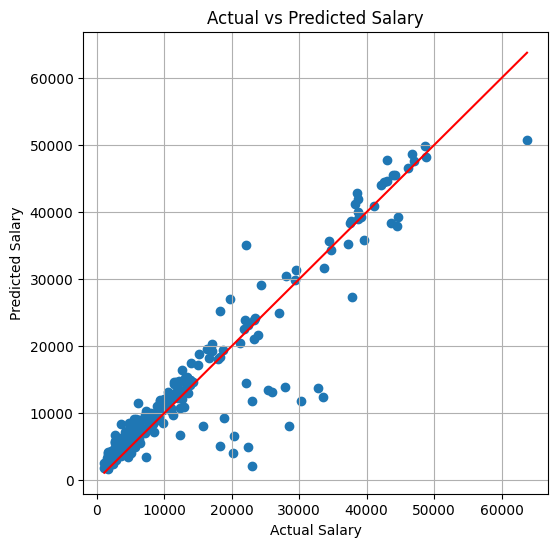

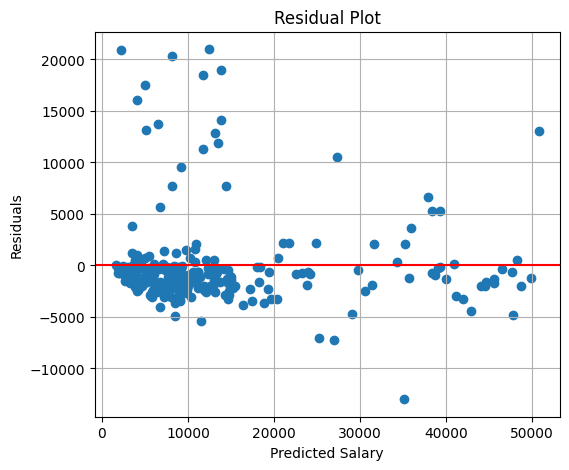


Sample Predictions
   Actual Salary  Predicted Salary
0    9095.068359      10215.082031
1    5272.175781       5690.385254
2   29330.984375      29804.912109
3    9301.893555      10919.400391
4   33750.292969      31639.714844
5    4536.259277       4796.474121
6    2117.339355       3142.429199
7   14210.536133      14665.567383
8    3732.625488       4914.546387
9   10264.442383      11366.372070

Conclusion

1. The neural network successfully learned the relationship between input
   features and salary.

2. Training loss continuously decreased, indicating effective learning.

3. The model achieved:

   • RMSE : 4428.78
   • MAE  : 2514.95
   • R²   : 0.8737

4. A lower RMSE and MAE indicate smaller prediction errors.

5. An R² score close to 1 means the model explains most of the variance
   in salary values.

6. The Actual vs Predicted graph should show points close to the diagonal
   line, indicating good prediction performance.



In [ ]:
# ============================================
# Salary Prediction using PyTorch
# ============================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim

# ============================================
# 2. Load Dataset
# ============================================

file_path = "salary.csv"     # Change to your file name
df = pd.read_csv("/content/insurance (3).csv")

print("First Five Rows:")
print(df.head())

print("\nDataset Information")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

# ============================================
# 3. Data Preprocessing
# ============================================

# Fill missing values
for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].mean(), inplace=True)

# Encode categorical columns
label_encoder = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = label_encoder.fit_transform(df[col])

# Features and Target
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values.reshape(-1,1)

# Feature Scaling
scalerX = StandardScaler()
X = scalerX.fit_transform(X)

scalerY = StandardScaler()
y = scalerY.fit_transform(y)

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Convert to Tensor
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)

y_train = torch.FloatTensor(y_train)
y_test = torch.FloatTensor(y_test)

# ============================================
# 4. Build PyTorch Neural Network
# ============================================

class SalaryModel(nn.Module):

    def __init__(self,input_size):
        super(SalaryModel,self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size,64),
            nn.ReLU(),

            nn.Linear(64,32),
            nn.ReLU(),

            nn.Linear(32,16),
            nn.ReLU(),

            nn.Linear(16,1)

        )

    def forward(self,x):
        return self.network(x)

model = SalaryModel(X_train.shape[1])

print(model)

# ============================================
# 5. Loss Function and Optimizer
# ============================================

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# ============================================
# 6. Training
# ============================================

epochs = 300

losses = []

for epoch in range(epochs):

    model.train()

    outputs = model(X_train)

    loss = criterion(outputs,y_train)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    if (epoch+1)%20==0:
        print(f"Epoch [{epoch+1}/{epochs}] Loss = {loss.item():.6f}")

# ============================================
# 7. Testing
# ============================================

model.eval()

with torch.no_grad():

    predictions = model(X_test)

# Convert back to original scale
predictions = scalerY.inverse_transform(predictions.numpy())

actual = scalerY.inverse_transform(y_test.numpy())

# ============================================
# 8. Evaluation Metrics
# ============================================

mse = mean_squared_error(actual,predictions)

rmse = np.sqrt(mse)

mae = mean_absolute_error(actual,predictions)

r2 = r2_score(actual,predictions)

print("\n==============================")
print("Evaluation Metrics")
print("==============================")

print("Mean Squared Error :",mse)
print("Root Mean Squared Error :",rmse)
print("Mean Absolute Error :",mae)
print("R2 Score :",r2)

# ============================================
# 9. Visualization
# ============================================

# Training Loss

plt.figure(figsize=(7,5))
plt.plot(losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# Actual vs Predicted

plt.figure(figsize=(6,6))
plt.scatter(actual,predictions)
plt.plot([actual.min(),actual.max()],
         [actual.min(),actual.max()],
         color='red')
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.grid(True)
plt.show()

# Residual Plot

residuals = actual - predictions

plt.figure(figsize=(6,5))
plt.scatter(predictions,residuals)
plt.axhline(y=0,color='red')
plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid(True)
plt.show()

# ============================================
# 10. Sample Predictions
# ============================================

results = pd.DataFrame({

    "Actual Salary":actual.flatten(),
    "Predicted Salary":predictions.flatten()

})

print("\nSample Predictions")
print(results.head(10))

# ============================================
# 11. Conclusion
# ============================================

print("\n==============================")
print("Conclusion")
print("==============================")

print(f"""
1. The neural network successfully learned the relationship between input
   features and salary.

2. Training loss continuously decreased, indicating effective learning.

3. The model achieved:

   • RMSE : {rmse:.2f}
   • MAE  : {mae:.2f}
   • R²   : {r2:.4f}

4. A lower RMSE and MAE indicate smaller prediction errors.

5. An R² score close to 1 means the model explains most of the variance
   in salary values.

6. The Actual vs Predicted graph should show points close to the diagonal
   line, indicating good prediction performance.
""")